In [1]:
import warnings
warnings.filterwarnings('ignore')

import sys,os
from copy import copy
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import scanpy as sc
import squidpy as sq
import numpy as np
import pandas as pd
from anndata import AnnData

from numpy.random import default_rng

import matplotlib.pyplot as plt
import networkx as nx


mpl.rcParams['figure.dpi'] = 50
mpl.rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(facecolor=(0, 0, 0, 0), dpi=50, dpi_save=600)

sns.set_style({'axes.grid': False})

In [2]:
os.environ["R_HOME"] = "/home/xuquan/miniconda3/envs/scarches057/lib/R" 
import rpy2
from rpy2.robjects import r


%load_ext rpy2.ipython

In [13]:
%%R 
library(ggplot2)
# library(ggpubr)
# library(patchwork)
# library(ggrepel)
# library(ComplexHeatmap)
# library(ggnewscale)
# library(tidygraph)
# library(ggraph)
library(circlize)

theme_set(
  theme_bw() +
    theme(legend.position = "top")
  )


R[write to console]: ========================================
circlize version 0.4.15
CRAN page: https://cran.r-project.org/package=circlize
Github page: https://github.com/jokergoo/circlize
Documentation: https://jokergoo.github.io/circlize_book/book/

If you use it in published research, please cite:
Gu, Z. circlize implements and enhances circular visualization
  in R. Bioinformatics 2014.

This message can be suppressed by:
  suppressPackageStartupMessages(library(circlize))




In [6]:
project_dir = '/home/xuquan/projects/pdac'
sc.settings.figdir = f'{project_dir}/figures/'
figdir = f'{project_dir}/figures/'

gns = copy(mpl.cm.Blues)
gns.set_under("lightgray")

plate_level_all0 = pd.read_csv(f"{project_dir}/db/pdac_color.txt",
                               sep='\t', header=None, index_col=0)
plate_level_all = plate_level_all0.to_dict()[1]
plate_level_all['nan'] = 'lightgray'

data_dir='/home/xuquan/projects/pdac/revision/data/spatial/Zohora_NM_2025'


In [3]:
def base_sp_ana(adata):
    adata.var_names_make_unique()

    sc.pp.calculate_qc_metrics(adata, inplace=True)

    adata = adata[adata.obs.n_genes_by_counts > 200, :]
    adata = adata[adata.obs.total_counts < 5e4, :]

    adata.var["mt"] = adata.var_names.str.startswith("MT-")
    sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], inplace=True)
    adata = adata[adata.obs.pct_counts_mt < 20, :]

    clear_genes = pd.read_csv("/home/xuquan/refgenomes/hg38/hg_genes_clear_new.txt", header=None)[0].tolist()
    malat1 = [i for i in clear_genes if i.startswith('MALAT1')]
    mito_genes = [i for i in clear_genes if i.startswith('MT-')]
    hb_genes = [i for i in clear_genes if i.startswith('^HB[^(P|E|S)]')]
    prl_genes = [i for i in clear_genes if i.startswith('^PR[(S|L)]')]
    xist = [i for i in clear_genes if i.startswith('XIST')]
    clear_genes = [i for i in clear_genes if i not in malat1+mito_genes+xist+prl_genes]

    sub_clear_genes = [i for i in clear_genes if i in adata.var.index.tolist()]
    adata = adata[:, sub_clear_genes]

    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)

    sc.pp.highly_variable_genes(
        adata,
        flavor="seurat_v3",
        n_top_genes=2000
    )

    adata.raw = adata
    adata = adata[:, adata.var.highly_variable]

    sc.pp.scale(adata)
    sc.tl.pca(adata)

    sc.pp.neighbors(adata, n_neighbors=15, n_pcs=30)
    sc.tl.umap(adata)
    
    return adata



In [16]:
project_dir = '/home/xuquan/projects/pdac'

nichenetr = pd.read_csv(f"{project_dir}/db/nichenetr_lr_network.txt", sep='\t')
l = nichenetr['from'].tolist()
r = nichenetr['to'].tolist()
all_lr = list(zip(nichenetr['from'],nichenetr['to']))


nichenetr = pd.read_csv(f"{project_dir}/db/lr_network_hg_Lignature.txt", sep='\t')
nichenetr['from'] = nichenetr['Lgene']
nichenetr['to'] = nichenetr['Rgene']
nichenetr = nichenetr.drop_duplicates(subset=['from', 'to'], keep='first')

l = nichenetr['Lgene'].tolist()
r = nichenetr['Rgene'].tolist()
all_lr = list(zip(nichenetr['Lgene'],nichenetr['Rgene']))



### procdata_64630

In [7]:

adata1 = sc.read_visium(
    path=f"{data_dir}/procdata_64630/",
    count_file="filtered_feature_bc_matrix.h5",
    load_images=True
)

adata1=base_sp_ana(adata1)
sc.tl.leiden(adata1, resolution=1)
sq.gr.spatial_neighbors(adata1,coord_type="grid")
sq.gr.nhood_enrichment(adata1, cluster_key="leiden")
leiden_nhood_enrichment = pd.DataFrame(adata1.uns['leiden_nhood_enrichment']['zscore'])


100%|██████████| 1000/1000 [00:00<00:00, 3551.02/s]


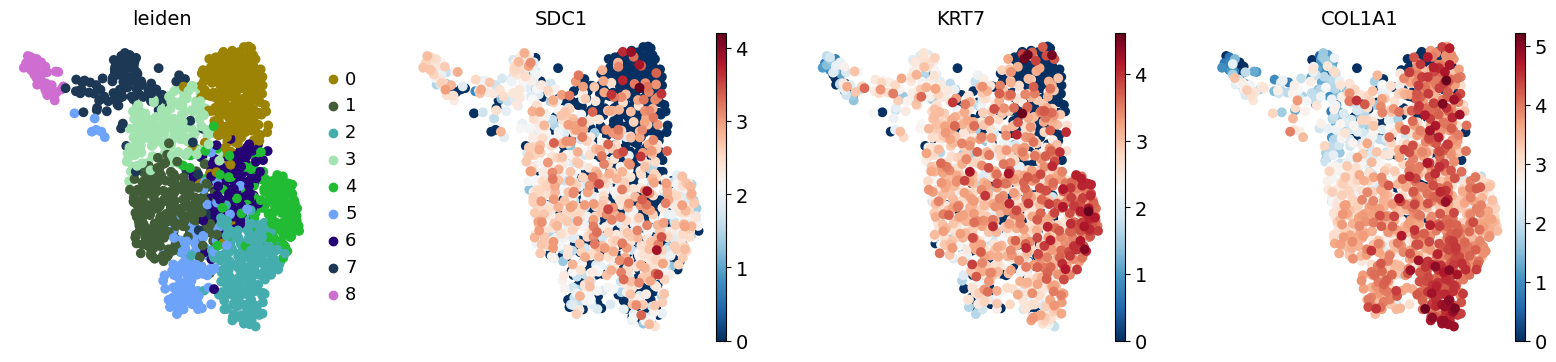

In [102]:

sc.pl.umap(adata1, color=["leiden",'SDC1','KRT7',"COL1A1"],
          cmap='RdBu_r', frameon=False, size=200, 
          palette=plate_level_all, ncols=4, wspace=0.2,
          save='procdata_64630_umap.pdf')


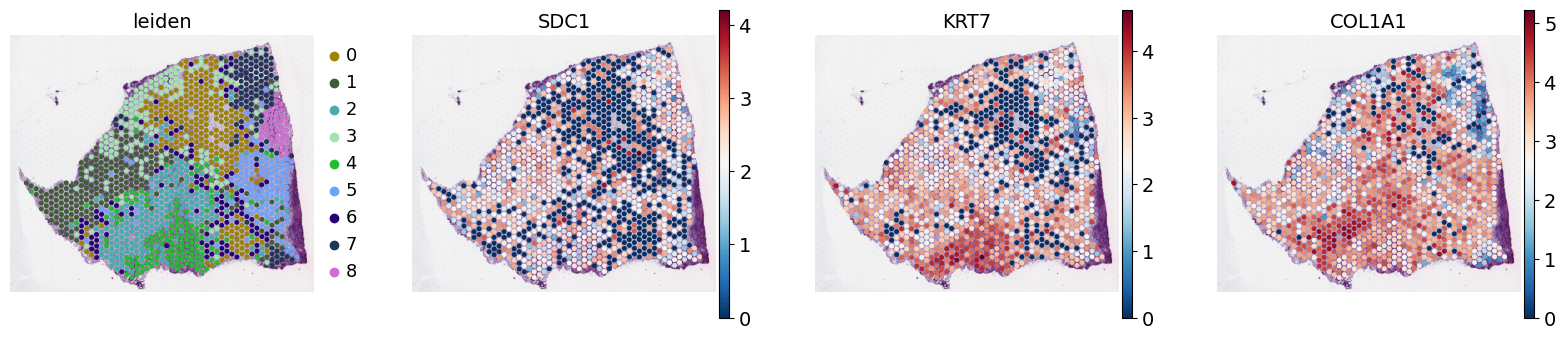

In [103]:
sc.pl.spatial(adata1, color=["leiden",'SDC1','KRT7',"COL1A1"], size=1.3,
              img_key="hires",frameon=False,cmap='RdBu_r',
              palette=plate_level_all, save='procdata_64630_sp.pdf')

In [ ]:
genes_to_plot = ['KRT19','SDC1','LAMB3','ITGA3','SDC4','CEACAM6',
                             'FAP',"COL1A1",'THBS1','FN1','COL1A2','GREM1',
                            'LOX','MMP14','SPARC','TIMP2','IGFBP5','PDGFRA','LRP1','TNFRSF12A']
keys_to_plot = []

for gene in genes_to_plot:
    expr = adata1.raw[:, gene].X
    expr = expr.toarray().flatten() if hasattr(expr, "toarray") else expr.flatten()

    v_min, v_max = expr.min(), expr.max()
    scaled = (expr - v_min) / (v_max - v_min) if v_max > v_min else expr

    # 存入 obs 并记录键名
    key = f"{gene}_raw_scaled"
    adata1.obs[key] = scaled
    keys_to_plot.append(key)

sc.pl.spatial(adata1, color=keys_to_plot, size=1.5,
              img_key=None,
              frameon=False,cmap='RdBu_r', 
              palette=plate_level_all, save='procdata_64630_sp_merscpe_genes.pdf')

# sc.pl.spatial(adata1,
# #                     adata1[(adata1.obsm['spatial'][:,1]>9000)&
# #                     (adata1.obsm['spatial'][:,0]>6000)&
# #                     (adata1.obsm['spatial'][:,0]<10000)&
# #                     (adata1.obs.leiden.isin(['2','4']))], 
              
#               color=['leiden',], size=1.5,
#               img_key=None,
#               frameon=False,cmap='RdBu_r', standard_scale="var", 
#               palette=plate_level_all, save='procdata_64630_sp_merscpe_genes.pdf')

In [51]:
# sc.pl.spatial(adata1[adata1.obs.leiden.isin(['2','4'])], color=['KRT19','SDC1','LAMB3','ITGA3','SDC4','CEACAM6',
#                              'FAP',"COL1A1",'THBS1','FN1','COL1A2','GREM1',
#                             'LOX','MMP14','SPARC','TIMP2','IGFBP5','PDGFRA','LRP1','TNFRSF12A'], size=1.3,
#               img_key=None,
#               frameon=False,cmap='RdBu_r',
#               palette=plate_level_all, save='procdata_64630_sp_merscpe_genes.pdf')

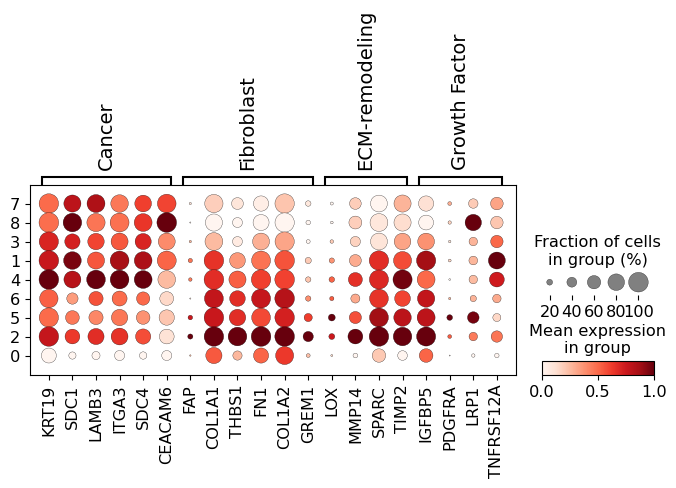

In [69]:
merscope_genes=['KRT19','SDC1','LAMB3','ITGA3','SDC4','CEACAM6',
                 'FAP',"COL1A1",'THBS1','FN1','COL1A2','GREM1',
                'LOX','MMP14','SPARC','TIMP2',
                'IGFBP5','PDGFRA','LRP1','TNFRSF12A']

# merscope_genes=['LAMB3','KRT8','KRT19','LAMB3','SDC4','PRSS8','CEACAM6','COL1A2','COL3A1','POSTN','SERPINE1']

# sc.tl.dendrogram(adata1,groupby="leiden",var_names=merscope_genes)

markers = {'Cancer':['KRT19','SDC1','LAMB3','ITGA3','SDC4','CEACAM6'],
           'Fibroblast':['FAP',"COL1A1",'THBS1','FN1','COL1A2','GREM1'],
           'ECM-remodeling':['LOX','MMP14','SPARC','TIMP2'],
           'Growth Factor':['IGFBP5','PDGFRA','LRP1','TNFRSF12A']
}
sc.pl.dotplot(adata1, 
              var_names=markers, 
                groupby="leiden",
                categories_order=['7','8','3','1','4','6','5','2','0'],
                standard_scale="var", 
              cmap="Reds", 
#               dendrogram=True, 
                figsize=(8,2.5), save='procdata_64630_sp_merscpe_genes.pdf')

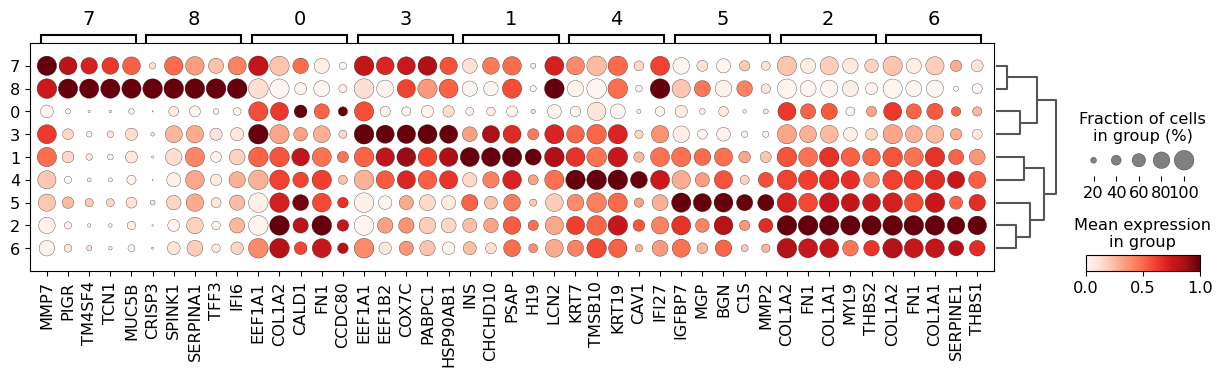

In [101]:
sc.tl.rank_genes_groups(adata1, 'leiden', method='wilcoxon', key_added = "wilcoxon")

rg = adata1.uns["wilcoxon"]
groups = rg["names"].dtype.names

markers = {
    group: rg["names"][group][:5]
    for group in groups
}

markers_df = pd.DataFrame()
for i in adata1.obs.leiden.unique():
    markers_df[i] = sc.get.rank_genes_groups_df(adata1, group=i, 
                    key='wilcoxon', pval_cutoff=0.01, log2fc_min=0)['names'].head(500)

sc.tl.dendrogram(adata1,groupby="leiden")

sc.pl.dotplot(adata1, var_names=markers, groupby="leiden",
                standard_scale="var", cmap="Reds", dendrogram=True, 
                figsize=(15,3), save='procdata_64630_topgenes.pdf')

In [11]:

def get_top_genes(adata1):

    # expr_df = pd.DataFrame(
    #     adata1.X,
    #     index=adata1.obs_names,
    #     columns=adata1.var_names
    # )

    expr_df = pd.DataFrame(
        adata1.raw.to_adata().to_df(),
        index=adata1.raw.to_adata().obs_names,
        columns=adata1.raw.to_adata().var_names
    )

    cluster_mean = (
        expr_df
        .groupby(adata1.obs['leiden'])
        .mean()
    )

    top_genes = {
        cluster: cluster_mean.loc[cluster].sort_values(ascending=False).head(500).index.tolist()
        for cluster in cluster_mean.index
    }
    top_genes = pd.DataFrame(top_genes)

    return top_genes
    # top_genes.to_csv(f"{data_dir}/procdata_64630_topgenes.txt", sep='\t')

def get_lr_df(top_genes):
    res_ls = []
    res_pairs_df = pd.DataFrame()

    for from_ct in top_genes.columns:
        for to_ct in top_genes.columns: 
            pairs = [i for i in all_lr if i[0] in top_genes[from_ct].tolist() and 
                            i[1] in top_genes[to_ct].tolist()]
            pairs_num = len(pairs)
            res_ls.append([from_ct, to_ct, pairs_num])
            if pairs_num==0:
                pairs_df = pd.DataFrame({'from':[],'to':[],'from_ct':[],'to_ct':[]})
            else:
                pairs_df = pd.DataFrame(pairs)
                pairs_df.columns=['from','to']
                pairs_df['from_ct'] = f'C{from_ct}'
                pairs_df['to_ct'] = f'C{to_ct}'
            res_pairs_df = pd.concat([res_pairs_df, pairs_df], axis=0)


    res_ls = pd.DataFrame(res_ls)
    res_ls.columns=['source','target','num']
    res_ls1 =res_ls.pivot(index='source',columns='target',values='num')
    
    return res_pairs_df,res_ls1

def get_lr_network(adata1, res_ls1, leiden_nhood_enrichment, enrich_cutoff=1):

    node_size_dict = adata1.obs.leiden.value_counts().to_dict()

    lower = res_ls1.where(np.tril(np.ones(res_ls1.shape), k=-1).astype(bool))
    upper = res_ls1.where(np.triu(np.ones(res_ls1.shape), k=1).astype(bool))

    sp_c = pd.DataFrame(adata1.obsm['spatial'])
    sp_c[1] = -sp_c[1]
    sp_c['leiden'] = adata1.obs.leiden.tolist()
    sp_c = sp_c.groupby('leiden').mean()

    G = nx.DiGraph()
    for cluster, row in sp_c.iterrows():
        G.add_node(cluster, pos=(row.iloc[0], row.iloc[1]))

    pos = nx.get_node_attributes(G, "pos")

    edges = (
        leiden_nhood_enrichment
    #     .where(np.triu(np.ones(leiden_nhood_enrichment.shape), k=1).astype(bool))
        .stack()
        .reset_index(name="enrich")
        .rename(columns={"level_0": "source", "level_1": "target"})
        .query("source != target")
        .query(f"enrich > {enrich_cutoff}")
    )

    edges.source = edges.source.astype("string")
    edges.target = edges.target.astype("string")

    edges["weight"] = res_ls1.to_numpy()[
        res_ls1.index.get_indexer(edges["source"]),
        res_ls1.columns.get_indexer(edges["target"])
    ]
    edges = edges.query("weight > 0")

    for _, row in edges.iterrows():
        G.add_edge(
            row["source"],
            row["target"],
            weight=row["weight"]
        )

    weights = np.array([G[u][v]["weight"] for u, v in G.edges()])
    edge_widths = 1 + 2 * (weights - weights.min()) / (weights.max() - weights.min())

    node_sizes = [
        node_size_dict.get(node, 300)*2
        for node in G.nodes()
    ]
    
    return G,pos,weights,edge_widths,node_sizes


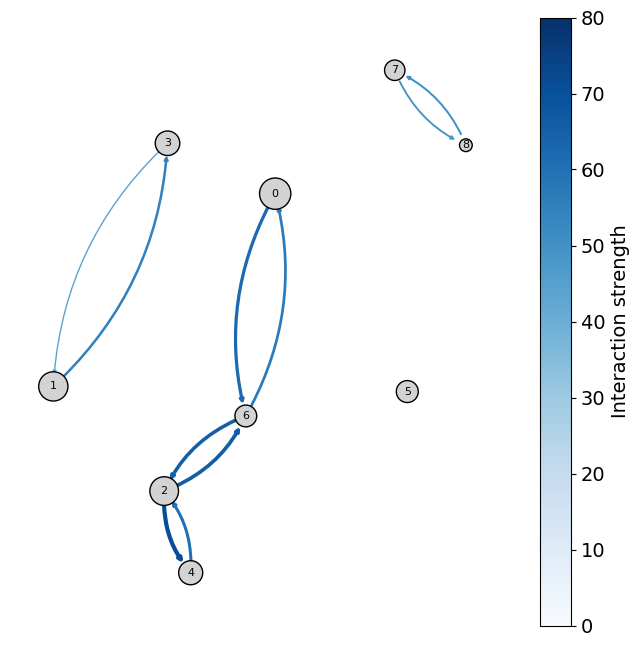

In [113]:
top_genes = get_top_genes(adata1)
res_pairs_df,res_ls1 = get_lr_df(top_genes)
G,pos,weights,edge_widths,node_sizes = get_lr_network(adata1, res_ls1, leiden_nhood_enrichment,0)

fig, ax = plt.subplots(figsize=(8, 8))

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=node_sizes,
    node_color="lightgray",
    edgecolors="black",
    ax=ax
)

nx.draw_networkx_edges(
    G,
    pos,
    width=edge_widths,
    connectionstyle="arc3,rad=0.2",
    edge_vmin=0,
    edge_vmax=80,
    arrowsize=5,
    alpha=1,
    edge_color=weights,
    edge_cmap=plt.cm.Blues,
    ax=ax
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=8,
    ax=ax
)

w_min, w_max = 0, 80
ax.set_axis_off()

# ---- Colorbar ----
sm = plt.cm.ScalarMappable(
    cmap=plt.cm.Blues,
    norm=plt.Normalize(vmin=w_min, vmax=w_max)
)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Interaction strength")

plt.savefig(f"{figdir}/procdata_64630_network.pdf", format="pdf")


In [36]:
sub_lr = res_pairs_df[(res_pairs_df['from_ct']=='C4')&(res_pairs_df['to_ct']=='C2')]
use_genes = list(set(sub_lr['from'].tolist()+sub_lr['to'].tolist()))
use_genes_col = ['#00A087' if i in sub_lr['from'].tolist() else '#3C5488' for i in use_genes]

sub_lr.head()

,from,to,from_ct,to_ct
0,COL1A1,ITGB1,C4,C2
1,COL1A1,ITGA3,C4,C2
2,FN1,ITGA3,C4,C2
3,FN1,ITGB1,C4,C2
4,SPP1,ITGB1,C4,C2


In [99]:
%%R -i sub_lr -i use_genes_col 

circos.clear()

sub_lr$from <- trimws(as.character(sub_lr$from))
sub_lr$to   <- trimws(as.character(sub_lr$to))

all_sectors <- unique(c(sub_lr$from, sub_lr$to))

from_count <- table(sub_lr$from)
to_count   <- table(sub_lr$to)

from_order <- names(sort(from_count, decreasing = TRUE))
to_order   <- names(sort(to_count, decreasing = TRUE))
sector.order <- c(from_order, to_order)

if (!setequal(sector.order, all_sectors)) {
  stop("Sector mismatch detected — investigate missing names.")
}


grid.col <- c(
  setNames(rep("#00A087", length(from_order)), from_order),
  setNames(rep("#3C5488", length(to_order)), to_order)
)

pdf("/home/xuquan/projects/pdac/figures/LR_C4C2_chord.pdf")

circos.par(start.degree = 0)
chordDiagram(
    sub_lr[, c("from", "to")],
    order = sector.order,
    grid.col = grid.col,
    col = "#333333",
    annotationTrack = "grid", 
    preAllocateTracks = 1, 
    transparency = 0.3
)

circos.trackPlotRegion(track.index = 1, panel.fun = function(x, y) {
    xlim = get.cell.meta.data("xlim")
    ylim = get.cell.meta.data("ylim")
    sector.name = get.cell.meta.data("sector.index")
    circos.text(mean(xlim), ylim[1] + .1, sector.name, facing = "clockwise", niceFacing = TRUE, adj = c(0, 0.5))
}, bg.border = NA)

# dev.off()


In [90]:
# res_pairs_df[(res_pairs_df['from_ct']=='C7')&(res_pairs_df['to_ct']=='C0')]

In [91]:
# res_pairs_df[(res_pairs_df['from_ct']=='C1')&(res_pairs_df['to_ct']=='C5')]

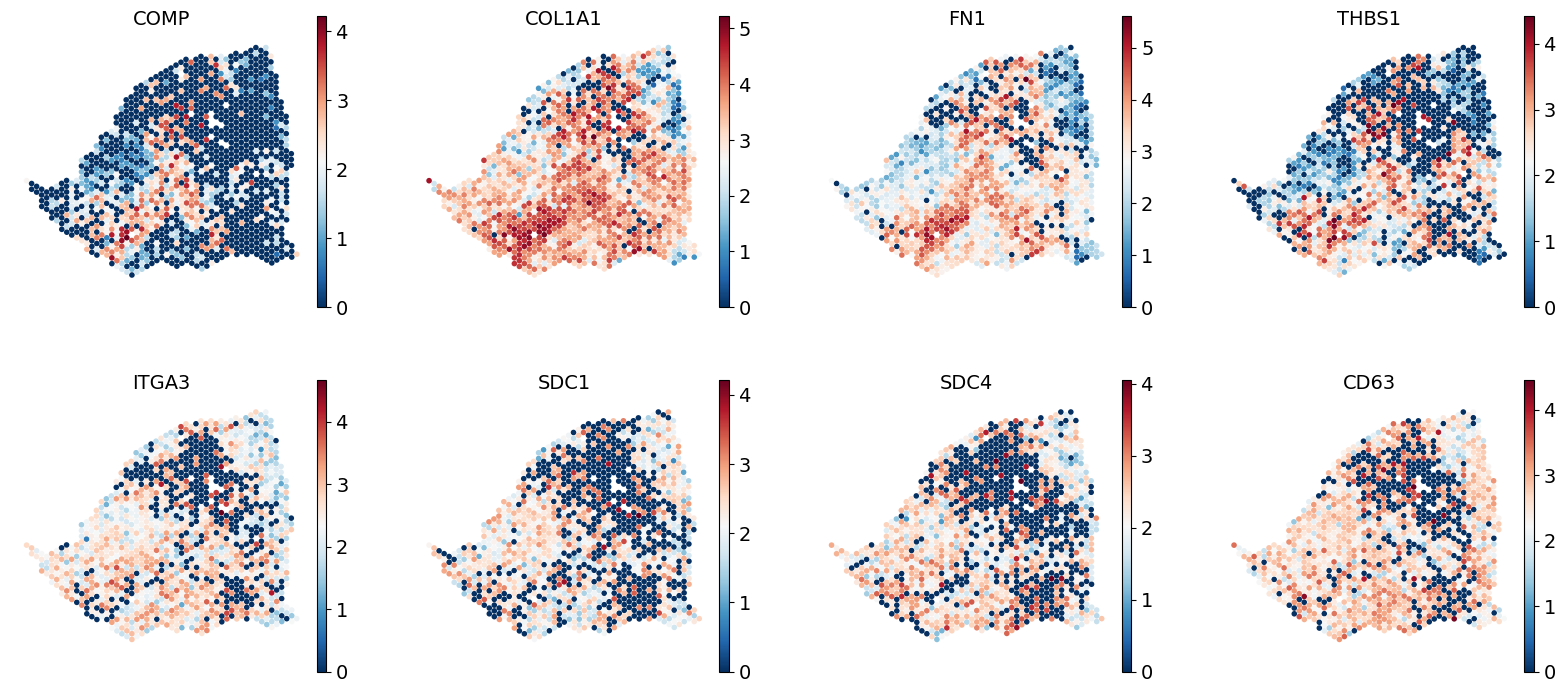

In [120]:
sc.pl.spatial(adata1, color=['COMP', 'COL1A1', 'FN1', 'THBS1',
                            'ITGA3', 'SDC1', 'SDC4', 'CD63'], size=1.5,
              img_key=None,
              frameon=False,cmap='RdBu_r',
              palette=plate_level_all, save='procdata_64630_sp_marker.pdf')

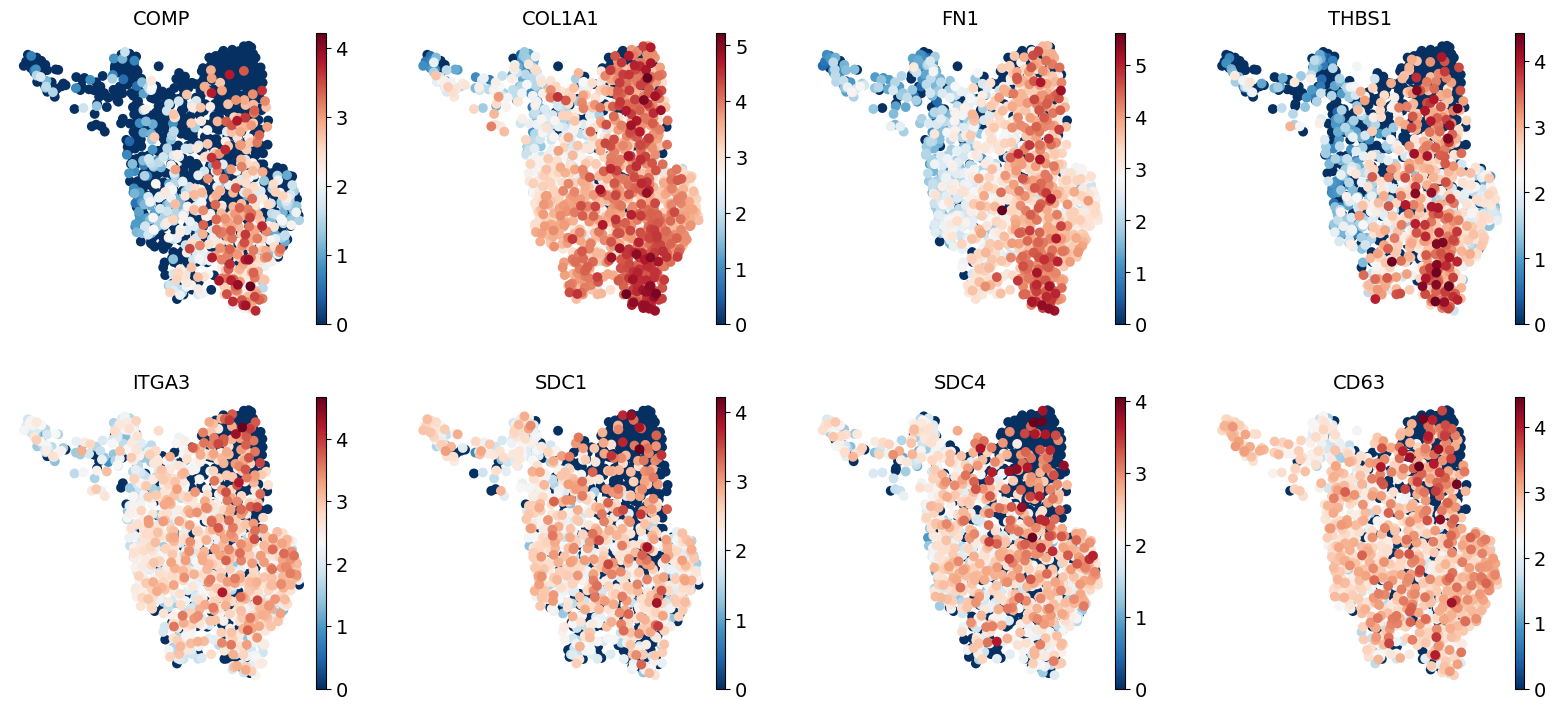

In [106]:

sc.pl.umap(adata1, color=['COMP', 'COL1A1', 'FN1', 'THBS1',
                            'ITGA3', 'SDC1', 'SDC4', 'CD63'],
          cmap='RdBu_r', frameon=False, size=200, 
          palette=plate_level_all, ncols=4, wspace=0.2,
          save='procdata_64630_sp_marker.pdf')


### procdata_140694

In [13]:

adata2 = sc.read_visium(
    path=f"{data_dir}/procdata_140694/",
    count_file="filtered_feature_bc_matrix.h5",
    load_images=True
)

adata2=base_sp_ana(adata2)
sc.tl.leiden(adata2, resolution=1)
sq.gr.spatial_neighbors(adata2,coord_type="grid")
sq.gr.nhood_enrichment(adata2, cluster_key="leiden")
leiden_nhood_enrichment = pd.DataFrame(adata2.uns['leiden_nhood_enrichment']['zscore'])


100%|██████████| 1000/1000 [00:00<00:00, 3004.37/s]


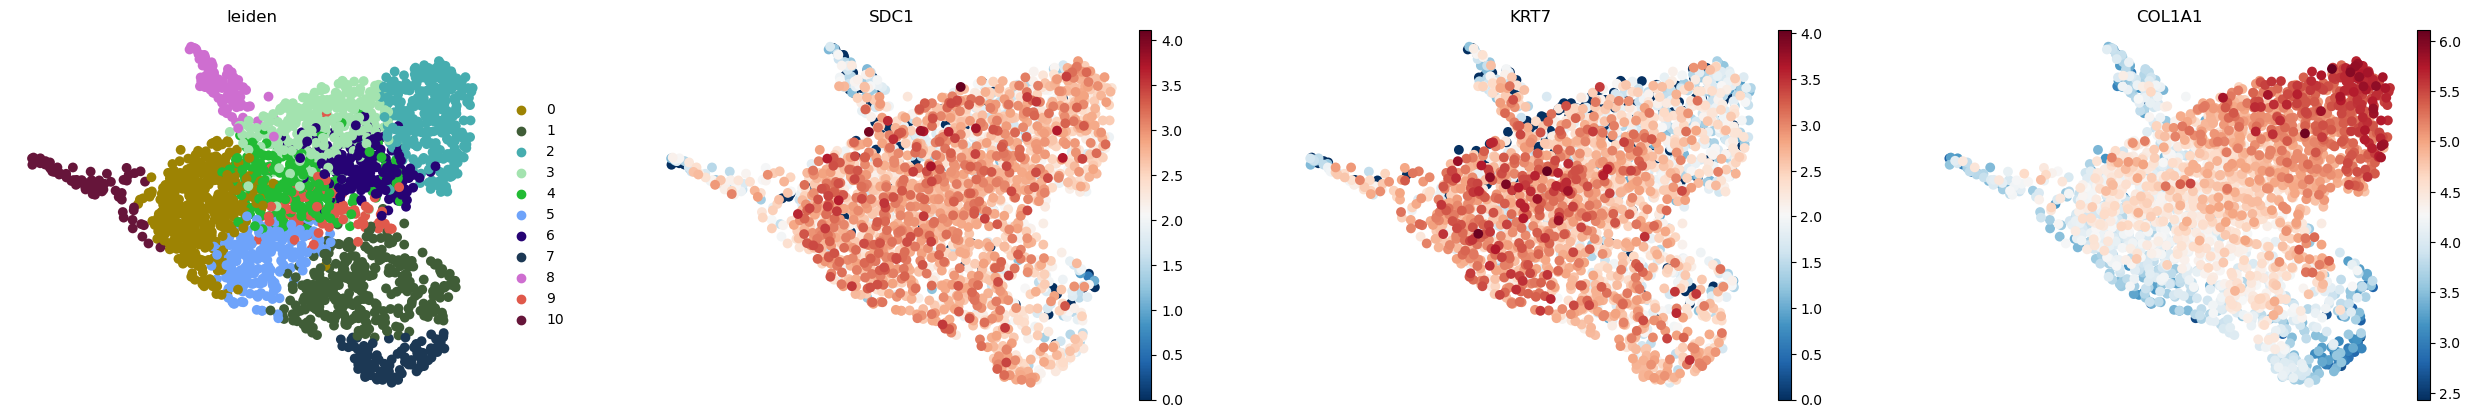

In [6]:
sc.pl.umap(adata2, color=["leiden",'SDC1','KRT7',"COL1A1"],
          cmap='RdBu_r', frameon=False, size=200, 
          palette=plate_level_all, ncols=4, wspace=0.2,
          save='procdata_140694_umap.pdf')


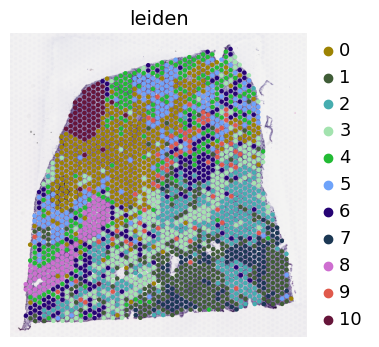

In [14]:
sc.pl.spatial(adata2, color="leiden", size=1.3,
    img_key="hires",frameon=False,palette=plate_level_all,
              save='procdata_140694_sp.pdf')

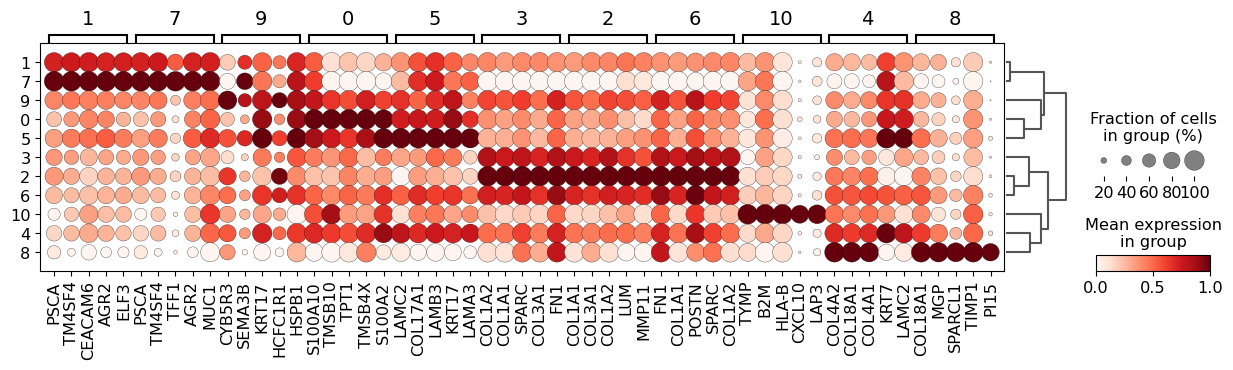

In [127]:
sc.tl.rank_genes_groups(adata2, 'leiden', method='wilcoxon', key_added = "wilcoxon")

rg = adata2.uns["wilcoxon"]
groups = rg["names"].dtype.names

markers = {
    group: rg["names"][group][:5]
    for group in groups
}

markers_df = pd.DataFrame()
for i in adata2.obs.leiden.unique():
    markers_df[i] = sc.get.rank_genes_groups_df(adata2, group=i, 
                    key='wilcoxon', pval_cutoff=0.01, log2fc_min=0)['names'].head(500)

sc.tl.dendrogram(adata2,groupby="leiden")

sc.pl.dotplot(adata2, var_names=markers, groupby="leiden",
                standard_scale="var", cmap="Reds", dendrogram=True, 
                figsize=(15,3),save='procdata_140694_topgenes.pdf')

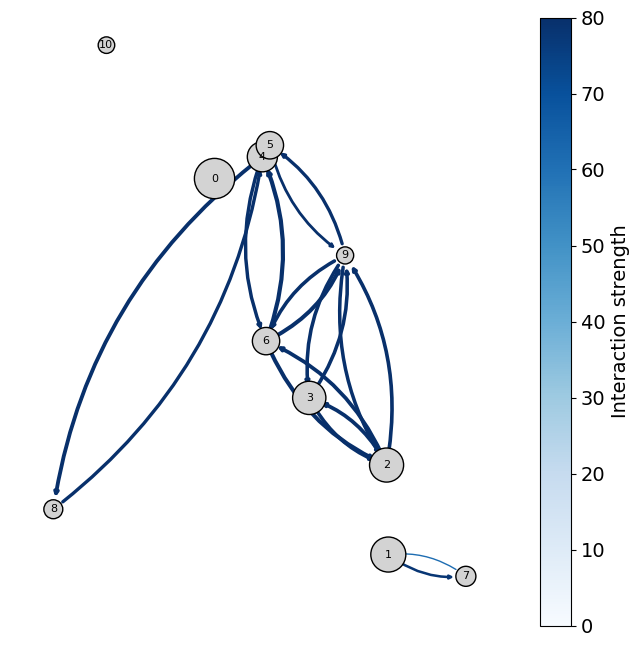

In [17]:
top_genes = get_top_genes(adata2)
res_pairs_df,res_ls1 = get_lr_df(top_genes)
G,pos,weights,edge_widths,node_sizes = get_lr_network(adata2, res_ls1, leiden_nhood_enrichment,0)

fig, ax = plt.subplots(figsize=(8, 8))

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=node_sizes,
    node_color="lightgray",
    edgecolors="black",
    ax=ax
)

nx.draw_networkx_edges(
    G,
    pos,
    width=edge_widths,
    connectionstyle="arc3,rad=0.2",
    edge_vmin=0,
    edge_vmax=80,
    arrowsize=5,
    alpha=1,
    edge_color=weights,
    edge_cmap=plt.cm.Blues,
    ax=ax
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=8,
    ax=ax
)

w_min, w_max = 0, 80
ax.set_axis_off()

# ---- Colorbar ----
sm = plt.cm.ScalarMappable(
    cmap=plt.cm.Blues,
    norm=plt.Normalize(vmin=w_min, vmax=w_max)
)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Interaction strength")

plt.savefig(f"{figdir}/procdata_140694_network.pdf", format="pdf")


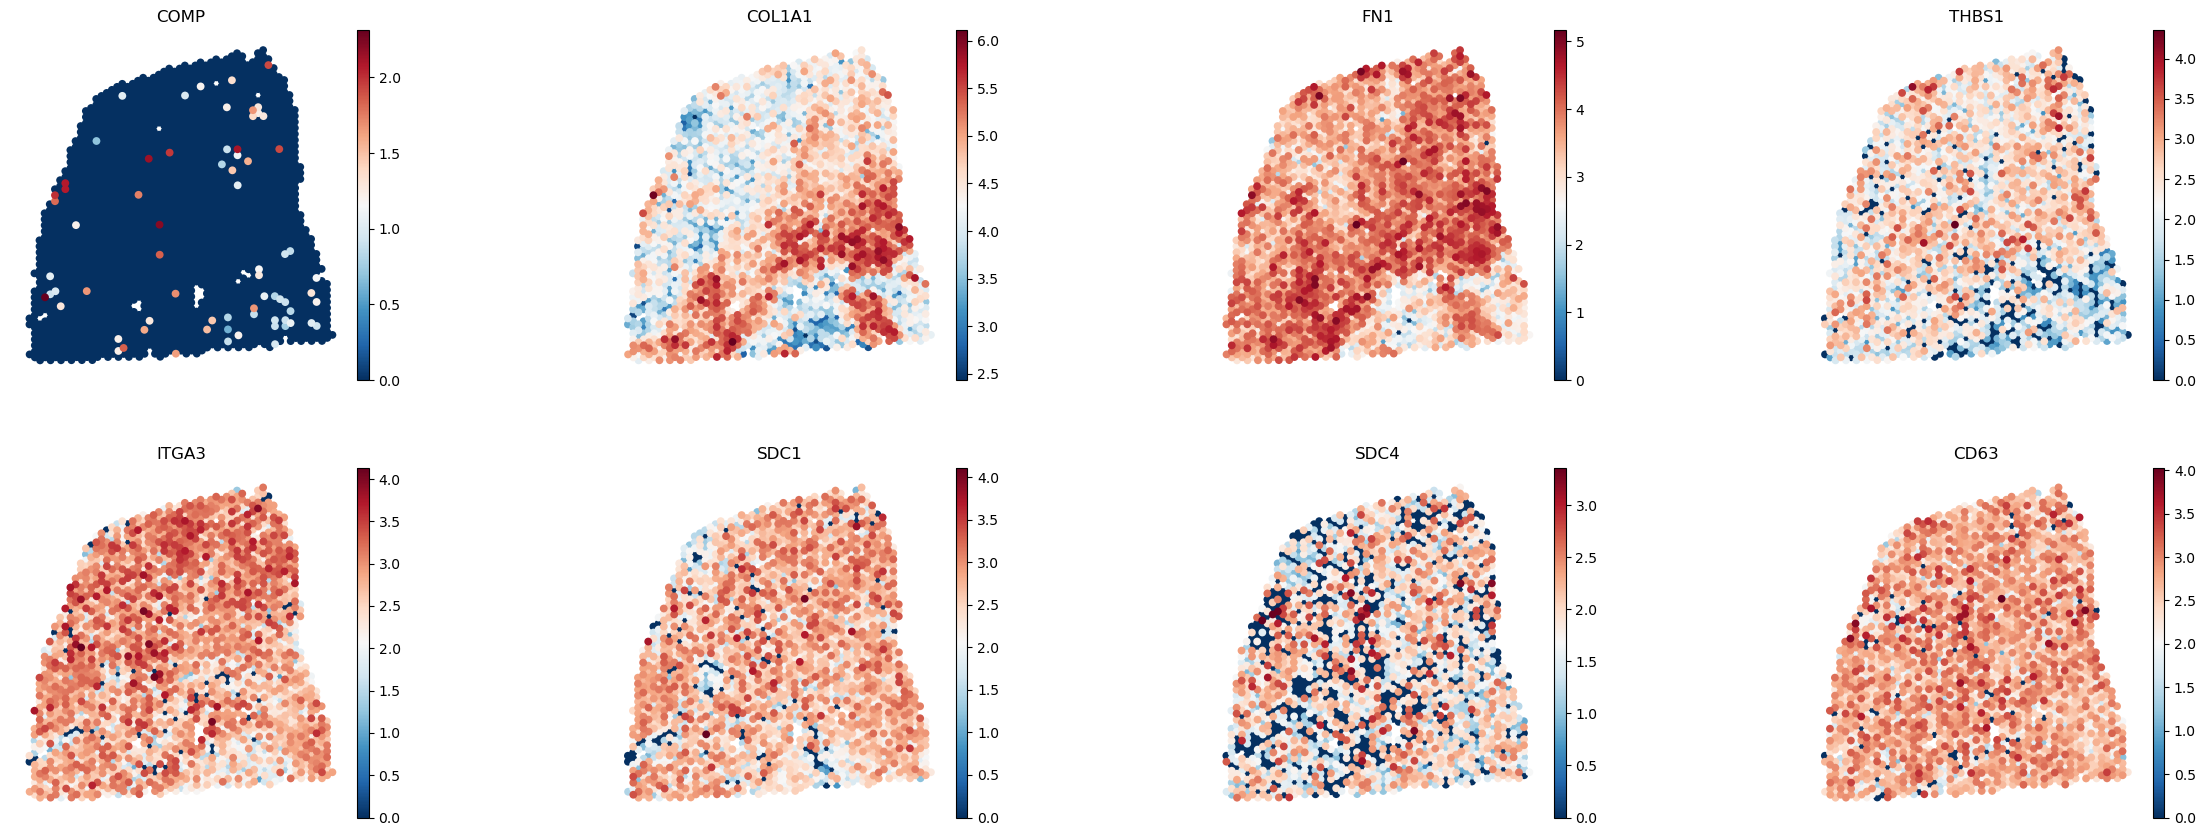

In [8]:
sc.pl.spatial(adata2, color=['COMP', 'COL1A1', 'FN1', 'THBS1',
                            'ITGA3', 'SDC1', 'SDC4', 'CD63'], size=2,
              img_key=None,
              frameon=False,cmap='RdBu_r',
              palette=plate_level_all, save='procdata_140694_sp_marker.pdf')

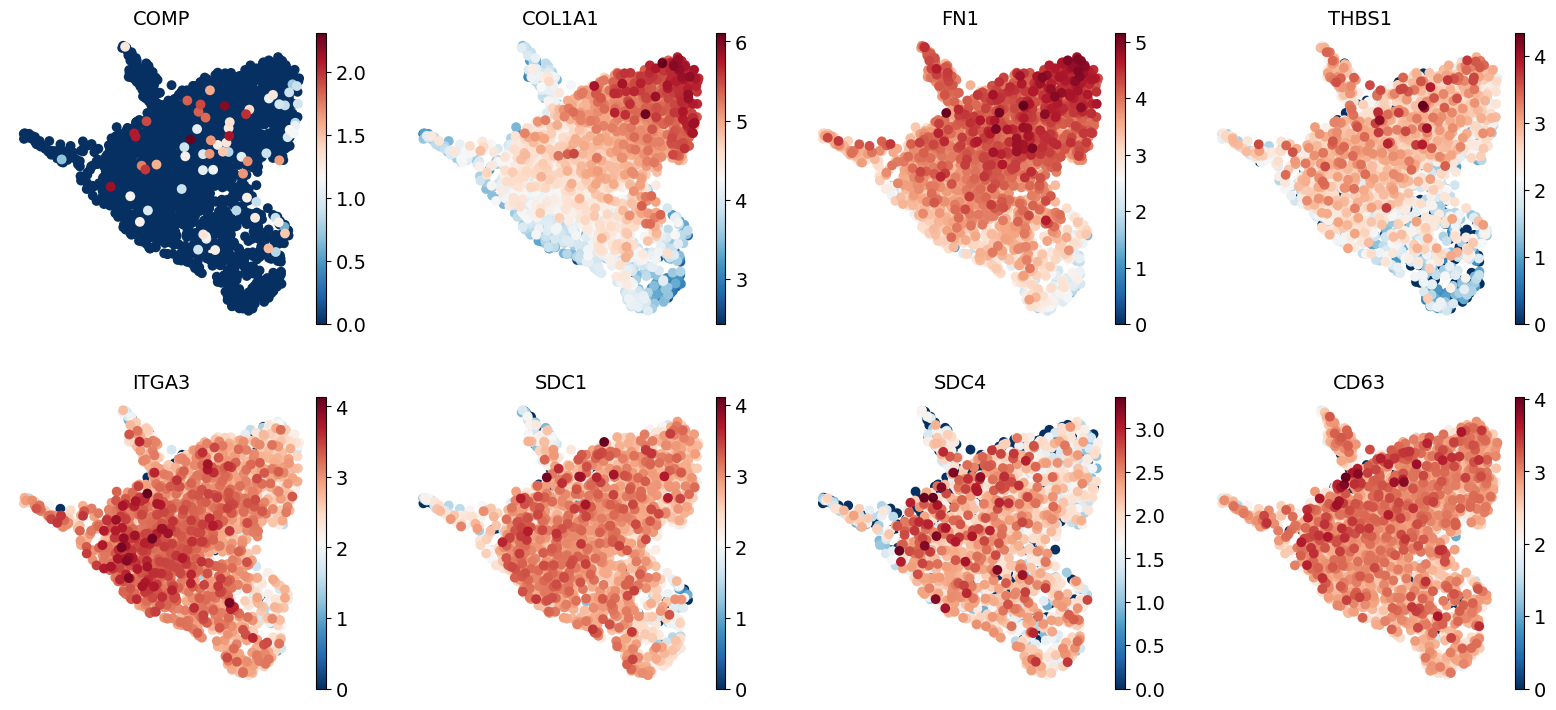

In [132]:

sc.pl.umap(adata2, color=['COMP', 'COL1A1', 'FN1', 'THBS1',
                            'ITGA3', 'SDC1', 'SDC4', 'CD63'],
          cmap='RdBu_r', frameon=False, size=200, 
          palette=plate_level_all, ncols=4, wspace=0.2,
          save='procdata_140694_sp_marker.pdf')


In [138]:
res_pairs_df[(res_pairs_df['epi_ct']=='C2')&(res_pairs_df['mes_ct']=='C3')]

,from,to,epi_ct,mes_ct
0,LAMC3,ITGA6,C2,C3
1,FN1,ITGB6,C2,C3
2,TNC,ITGB6,C2,C3
3,LAMC3,ITGB4,C2,C3
4,ADAM12,SDC4,C2,C3
5,CCL11,ACKR4,C2,C3
6,CCL13,ACKR4,C2,C3
7,CCN1,SDC4,C2,C3
8,F10,F3,C2,C3
9,HLA-A,APLP2,C2,C3
